# Gaming Influencer Selection: YouTube Engagement & Sentiment Analysis
Ranking 5 gaming YouTubers for an influencer campaign using views, engagement rate and audience comment sentiment (VADER).

In [14]:

import pandas as pd
from googleapiclient.discovery import build
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
import seaborn as sns
import re
import random
from google.colab import filesimport os
from getpass import getpass


## 1. Collect video data (YouTube Data API v3)
Videos published April–June 2026.

In [1]:

# Get a free key from Google Cloud Console (YouTube Data API v3).
# Never paste the key directly into the notebook.
API_KEY = os.environ.get("YOUTUBE_API_KEY") or getpass("YouTube API key: ")

youtube = build(
    "youtube",
    "v3",
    developerKey=API_KEY
)


CHANNELS = [
    "@lachlan",
    "@PrestonPlayz",
    "@TypicalGamer",
    "@theRadBrad",
    "@H2ODelirious"
]

START = "2026-04-01T00:00:00Z"
END   = "2026-07-01T00:00:00Z"


data = []
video_ids = {}




for handle in CHANNELS:

    ch = youtube.channels().list(
        part="snippet,contentDetails",
        forHandle=handle
    ).execute()["items"][0]


    channel_name = ch["snippet"]["title"]

    uploads = ch["contentDetails"]["relatedPlaylists"]["uploads"]


    ids, next_page = [], None

    while True:

        res = youtube.playlistItems().list(
            part="contentDetails",
            playlistId=uploads,
            maxResults=50,
            pageToken=next_page
        ).execute()


        batch = [
            (
                i["contentDetails"]["videoId"],
                i["contentDetails"]["videoPublishedAt"]
            )
            for i in res["items"]
            if i["contentDetails"].get("videoPublishedAt")
        ]


        ids += [
            v for v, p in batch
            if START <= p < END
        ]


        next_page = res.get("nextPageToken")


        if not next_page:
            break


    video_ids[channel_name] = ids


    # بيانات الفيديوهات

    for i in range(0, len(ids), 50):

        response = youtube.videos().list(
            part="snippet,statistics",
            id=",".join(ids[i:i+50]),
            maxResults=50
        ).execute()


        for item in response["items"]:

            data.append({

                "Channel_Name": channel_name,

                "Video_ID": item["id"],

                "Title": item["snippet"]["title"],

                "Date": item["snippet"]["publishedAt"],

                "Views": int(item["statistics"].get("viewCount",0)),

                "Likes": int(item["statistics"].get("likeCount",0)),

                "Comments": int(item["statistics"].get("commentCount",0))

            })


    print(f"{channel_name}: {len(ids)} Video")


df = pd.DataFrame(data)

df

,Channel_Name,Video_ID,Title,Date,Views,Likes,Comments
0,Lachlan,hbx2Fz3ULt8,What Do You Call This?,2026-06-29T16:00:27Z,2312785,68135,408
1,Lachlan,-r_vMb74ctA,I Hosted a 1HP Tournament!,2026-06-24T11:00:23Z,343448,6483,189
2,Lachlan,sma9dpRQ1xE,Do NOT Open This Chest...,2026-06-11T16:00:07Z,569542,11100,116
3,Lachlan,uM7-jyCANFs,I Found Fortnite's RAREST Sprite... Kinda,2026-06-09T13:04:27Z,4004828,79042,1372
4,Lachlan,oyNcgpBkufo,"Win Duck Race = 10,000 Vbucks!",2026-06-07T16:00:19Z,786451,13793,66
...,...,...,...,...,...,...,...
262,H2ODelirious,nee4GvW59U8,BURNT PEANUTS RUST SERVER FUNNY MOMENTS!,2026-04-06T02:48:20Z,114951,4774,218
263,H2ODelirious,z2q1PQRjj7s,EXPANDING THE STORE! - THE WALKING TRADE PART 3!,2026-04-05T01:40:49Z,72521,3102,266
264,H2ODelirious,TP4ec4T3qK8,ZOMBIES HATE STORES! - THE WALKING TRADE PART 2!,2026-04-03T22:53:38Z,66377,2962,194
265,H2ODelirious,gdk7bTpLjbY,THE WALKING DEAD... I MEAN THE WALKING TRADE P...,2026-04-03T00:01:21Z,126922,5203,296


## 2. Engagement analysis

In [2]:
df["Engagement_Rate"] = (

    (df["Likes"] + df["Comments"]) /
    df["Views"].replace(0,1)

) * 100


df

,Channel_Name,Video_ID,Title,Date,Views,Likes,Comments,Engagement_Rate
0,Lachlan,hbx2Fz3ULt8,What Do You Call This?,2026-06-29T16:00:27Z,2312785,68135,408,2.963656
1,Lachlan,-r_vMb74ctA,I Hosted a 1HP Tournament!,2026-06-24T11:00:23Z,343448,6483,189,1.942652
2,Lachlan,sma9dpRQ1xE,Do NOT Open This Chest...,2026-06-11T16:00:07Z,569542,11100,116,1.969302
3,Lachlan,uM7-jyCANFs,I Found Fortnite's RAREST Sprite... Kinda,2026-06-09T13:04:27Z,4004828,79042,1372,2.007926
4,Lachlan,oyNcgpBkufo,"Win Duck Race = 10,000 Vbucks!",2026-06-07T16:00:19Z,786451,13793,66,1.762220
...,...,...,...,...,...,...,...,...
262,H2ODelirious,nee4GvW59U8,BURNT PEANUTS RUST SERVER FUNNY MOMENTS!,2026-04-06T02:48:20Z,114951,4774,218,4.342720
263,H2ODelirious,z2q1PQRjj7s,EXPANDING THE STORE! - THE WALKING TRADE PART 3!,2026-04-05T01:40:49Z,72521,3102,266,4.644172
264,H2ODelirious,TP4ec4T3qK8,ZOMBIES HATE STORES! - THE WALKING TRADE PART 2!,2026-04-03T22:53:38Z,66377,2962,194,4.754659
265,H2ODelirious,gdk7bTpLjbY,THE WALKING DEAD... I MEAN THE WALKING TRADE P...,2026-04-03T00:01:21Z,126922,5203,296,4.332582


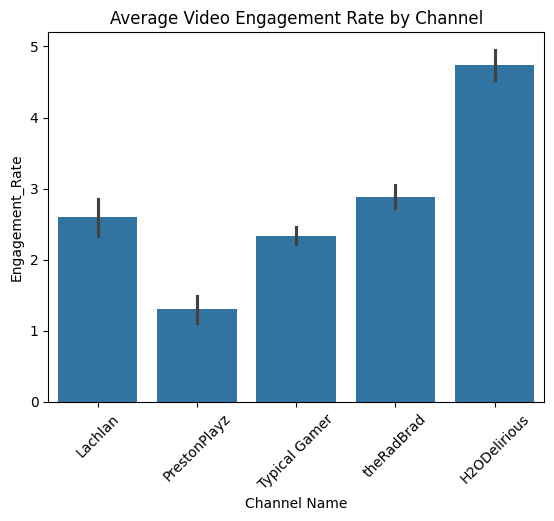

In [11]:
sns.barplot(
    data=df,
    x="Channel_Name",
    y="Engagement_Rate"
)

plt.title("Average Video Engagement Rate by Channel")

plt.xlabel("Channel Name")

plt.xticks(rotation=45)

plt.show()

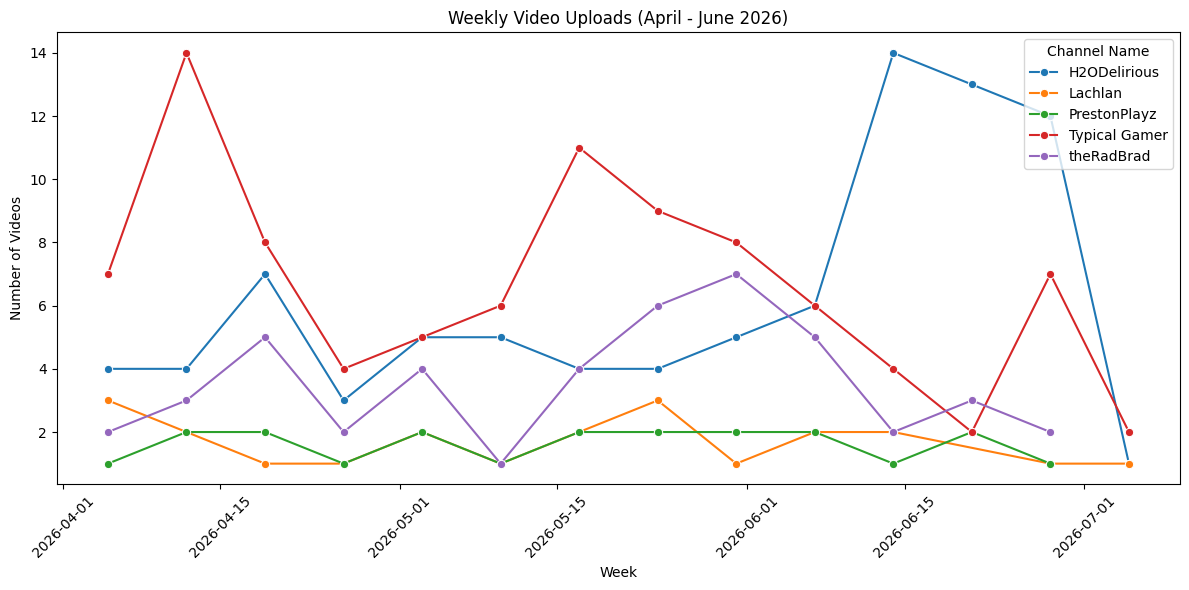

In [ ]:

df["Date"] = pd.to_datetime(df["Date"])

weekly_uploads = (
    df.groupby([
        "Channel_Name",
        pd.Grouper(key="Date", freq="W")
    ])
    .size()
    .reset_index(name="Videos")
)


plt.figure(figsize=(12,6))

sns.lineplot(
    data=weekly_uploads,
    x="Date",
    y="Videos",
    hue="Channel_Name",
    marker="o"
)


plt.title("Weekly Video Uploads (April - June 2026)")

plt.xlabel("Week")

plt.ylabel("Number of Videos")

plt.xticks(rotation=45)

plt.legend(title="Channel Name")

plt.tight_layout()

plt.show()

## 3. Collect & clean comments
Random 15% sample of each video's comments (max 300 per video).

In [4]:
comments = []

RATE = 0.15
CAP = 300


for channel_name, ids in video_ids.items():

    for vid in ids:

        video_comments = []
        next_page = None


        while True:

            try:

                response = youtube.commentThreads().list(

                    part="snippet",
                    videoId=vid,
                    maxResults=100,
                    pageToken=next_page,
                    order="time",
                    textFormat="plainText"

                ).execute()

            except Exception:

                break


            for item in response["items"]:

                video_comments.append({

                    "Channel_Name": channel_name,

                    "Video_ID": vid,

                    "Comment": item["snippet"]["topLevelComment"]["snippet"]["textDisplay"]

                })


            next_page = response.get("nextPageToken")


            if not next_page:
                break


        sample = min(
            max(1, int(len(video_comments) * RATE)),
            CAP
        )


        comments.extend(
            random.sample(video_comments, sample)
        )


    print(f"{channel_name}: Done")


comments_df = pd.DataFrame(comments)

comments_df.head()

Lachlan: Done
PrestonPlayz: Done
Typical Gamer: Done
theRadBrad: Done
H2ODelirious: Done


,Channel_Name,Video_ID,Comment
0,Lachlan,hbx2Fz3ULt8,I thought it was called the Pee Nut Butt Hurt ...
1,Lachlan,hbx2Fz3ULt8,NUT BUTTER 🤤
2,Lachlan,hbx2Fz3ULt8,DORITO
3,Lachlan,hbx2Fz3ULt8,Dorito
4,Lachlan,hbx2Fz3ULt8,I called that the triangle the whole time


In [5]:
def clean_text(text):

    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


comments_df["Clean_Comment"] = comments_df["Comment"].apply(clean_text)

## 4. Sentiment analysis (VADER)
Positive if compound > 0.05, Negative if < -0.05, otherwise Neutral.

In [6]:
analyzer = SentimentIntensityAnalyzer()


comments_df["Score"] = comments_df["Clean_Comment"].apply(
    lambda x: analyzer.polarity_scores(x)["compound"]
)


comments_df["Sentiment"] = comments_df["Score"].apply(
    lambda x:
    "Positive" if x > 0.05
    else "Negative" if x < -0.05
    else "Neutral"
)


comments_df.head()

,Channel_Name,Video_ID,Comment,Clean_Comment,Score,Sentiment
0,Lachlan,hbx2Fz3ULt8,I thought it was called the Pee Nut Butt Hurt ...,i thought it was called the pee nut butt hurt ...,-0.5267,Negative
1,Lachlan,hbx2Fz3ULt8,NUT BUTTER 🤤,nut butter,0.0000,Neutral
2,Lachlan,hbx2Fz3ULt8,DORITO,dorito,0.0000,Neutral
3,Lachlan,hbx2Fz3ULt8,Dorito,dorito,0.0000,Neutral
4,Lachlan,hbx2Fz3ULt8,I called that the triangle the whole time,i called that the triangle the whole time,0.0000,Neutral


In [7]:
sentiment_summary = comments_df.groupby(
    ["Channel_Name", "Sentiment"]
).size().unstack(fill_value=0)


sentiment_percentage = (
    sentiment_summary.div(
        sentiment_summary.sum(axis=1),
        axis=0
    ) * 100
)


sentiment_percentage

Sentiment,Negative,Neutral,Positive
Channel_Name,,,
H2ODelirious,15.115590,40.486070,44.398340
Lachlan,20.040900,55.214724,24.744376
PrestonPlayz,14.022383,61.092824,24.884793
Typical Gamer,8.923513,52.620397,38.456091
theRadBrad,19.571568,31.483285,48.945148


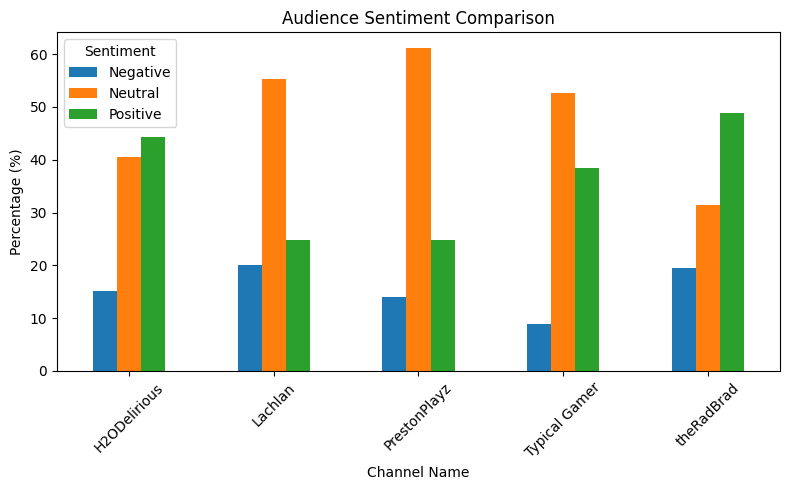

In [8]:
sentiment_percentage.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Audience Sentiment Comparison")
plt.ylabel("Percentage (%)")
plt.xlabel("Channel Name")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Influencer score
Weighted score: 40% median views + 35% engagement rate + 25% positive sentiment (percentile ranks).

In [9]:

channel_result = df.groupby("Channel_Name").agg(
    Videos=("Video_ID", "count"),
    Avg_Views=("Views", "mean"),
    Median_Views=("Views", "median"),
    Avg_Engagement=("Engagement_Rate", "mean")
).reset_index()


channel_result = channel_result.merge(
    sentiment_percentage.reset_index(),
    on="Channel_Name"
)



channel_result["Views_Score"] = (
    channel_result["Median_Views"].rank(pct=True)
)

channel_result["Engagement_Score"] = (
    channel_result["Avg_Engagement"].rank(pct=True)
)

channel_result["Sentiment_Score"] = (
    channel_result["Positive"].rank(pct=True)
)



channel_result["Influencer_Score"] = (
    channel_result["Views_Score"] * 0.40 +
    channel_result["Engagement_Score"] * 0.35 +
    channel_result["Sentiment_Score"] * 0.25
) * 100


channel_result = channel_result.sort_values(
    "Influencer_Score",
    ascending=False
)


channel_result[[
    "Channel_Name",
    "Videos",
    "Avg_Views",
    "Median_Views",
    "Avg_Engagement",
    "Positive",
    "Influencer_Score"
]]

,Channel_Name,Videos,Avg_Views,Median_Views,Avg_Engagement,Positive,Influencer_Score
4,theRadBrad,46,4.620703e+05,302185.5,2.885542,48.945148,77.0
0,H2ODelirious,87,1.644260e+05,86263.0,4.734855,44.398340,63.0
1,Lachlan,20,8.854333e+05,370974.0,2.593834,24.744376,58.0
2,PrestonPlayz,21,2.474217e+06,2511472.0,1.300702,24.884793,57.0
3,Typical Gamer,93,1.469069e+05,91494.0,2.334921,38.456091,45.0


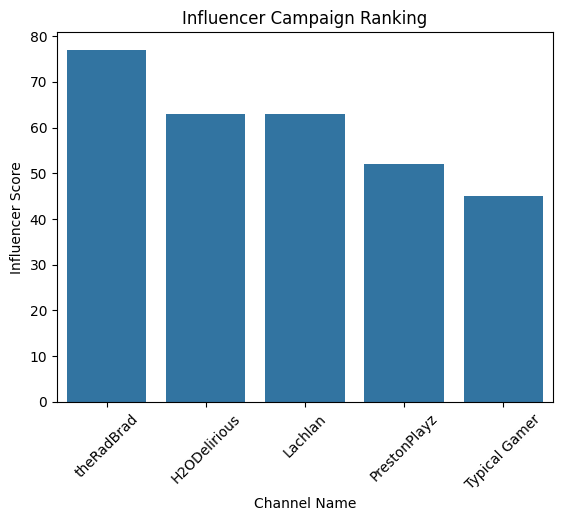

In [ ]:
sns.barplot(
    data=channel_result,
    x="Channel_Name",
    y="Influencer_Score"
)

plt.title("Influencer Campaign Ranking")
plt.xlabel("Channel Name")
plt.ylabel("Influencer Score")
plt.xticks(rotation=45)
plt.show()

In [ ]:
final_result = df.merge(
    sentiment_percentage.reset_index(),
    on="Channel_Name"
)

final_result

,Channel_Name,Video_ID,Title,Date,Views,Likes,Comments,Engagement_Rate,Negative,Neutral,Positive
0,Lachlan,hbx2Fz3ULt8,What Do You Call This?,2026-06-29 16:00:27+00:00,2275076,67448,407,2.982538,18.813906,55.623722,25.562372
1,Lachlan,-r_vMb74ctA,I Hosted a 1HP Tournament!,2026-06-24 11:00:23+00:00,342034,6460,189,1.943959,18.813906,55.623722,25.562372
2,Lachlan,sma9dpRQ1xE,Do NOT Open This Chest...,2026-06-11 16:00:07+00:00,569354,11098,116,1.969601,18.813906,55.623722,25.562372
3,Lachlan,uM7-jyCANFs,I Found Fortnite's RAREST Sprite... Kinda,2026-06-09 13:04:27+00:00,4003948,79036,1372,2.008218,18.813906,55.623722,25.562372
4,Lachlan,oyNcgpBkufo,"Win Duck Race = 10,000 Vbucks!",2026-06-07 16:00:19+00:00,786223,13791,66,1.762477,18.813906,55.623722,25.562372
...,...,...,...,...,...,...,...,...,...,...,...
262,H2ODelirious,nee4GvW59U8,BURNT PEANUTS RUST SERVER FUNNY MOMENTS!,2026-04-06 02:48:20+00:00,114941,4774,218,4.343098,15.717675,40.332147,43.950178
263,H2ODelirious,z2q1PQRjj7s,EXPANDING THE STORE! - THE WALKING TRADE PART 3!,2026-04-05 01:40:49+00:00,72499,3102,266,4.645581,15.717675,40.332147,43.950178
264,H2ODelirious,TP4ec4T3qK8,ZOMBIES HATE STORES! - THE WALKING TRADE PART 2!,2026-04-03 22:53:38+00:00,66351,2961,194,4.755015,15.717675,40.332147,43.950178
265,H2ODelirious,gdk7bTpLjbY,THE WALKING DEAD... I MEAN THE WALKING TRADE P...,2026-04-03 00:01:21+00:00,126882,5202,296,4.333160,15.717675,40.332147,43.950178


In [15]:
# Overall totals by channel

overall_totals = df.groupby("Channel_Name").agg(
    Total_Videos=("Video_ID", "nunique"),
    Total_Views=("Views", "sum"),
    Total_Likes=("Likes", "sum"),
    Total_Comments=("Comments", "sum")
).reset_index()

overall_totals

,Channel_Name,Total_Videos,Total_Views,Total_Likes,Total_Comments
0,H2ODelirious,87,14305061,732773,17019
1,Lachlan,20,17708666,437481,4536
2,PrestonPlayz,21,51958567,640162,28415
3,Typical Gamer,93,13662338,321128,11811
4,theRadBrad,46,21255232,559024,27035


## 6. Save results

In [18]:
if "final_result" not in globals():
    final_result = df.merge(
        sentiment_percentage.reset_index(),
        on="Channel_Name"
    )

# Save files
final_result.to_csv("final_results.csv", index=False)
comments_df.to_csv("comments_results.csv", index=False)
channel_result.to_csv("influencer_ranking.csv", index=False)
overall_totals.to_csv("overall_totals.csv", index=False)
